<a href="https://colab.research.google.com/github/vera2005/MLCV_course1/blob/main/Lesson6/Lesson6_FULL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Подготовка окружения

In [1]:
# Устанавливаем библиотеку Ultralytics (содержит YOLOv8)
!pip install ultralytics -q

import torch
print("GPU доступен:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Модель GPU:", torch.cuda.get_device_name(0))

GPU доступен: True
Модель GPU: Tesla T4


Загружаем сеть и кормим ее картинкой

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

image 1/1 /content/zidane.jpg: 384x640 2 persons, 1 tie, 9.1ms
Speed: 82.3ms preprocess, 9.1ms inference, 34.9ms postprocess per image at shape (1, 3, 384, 640)


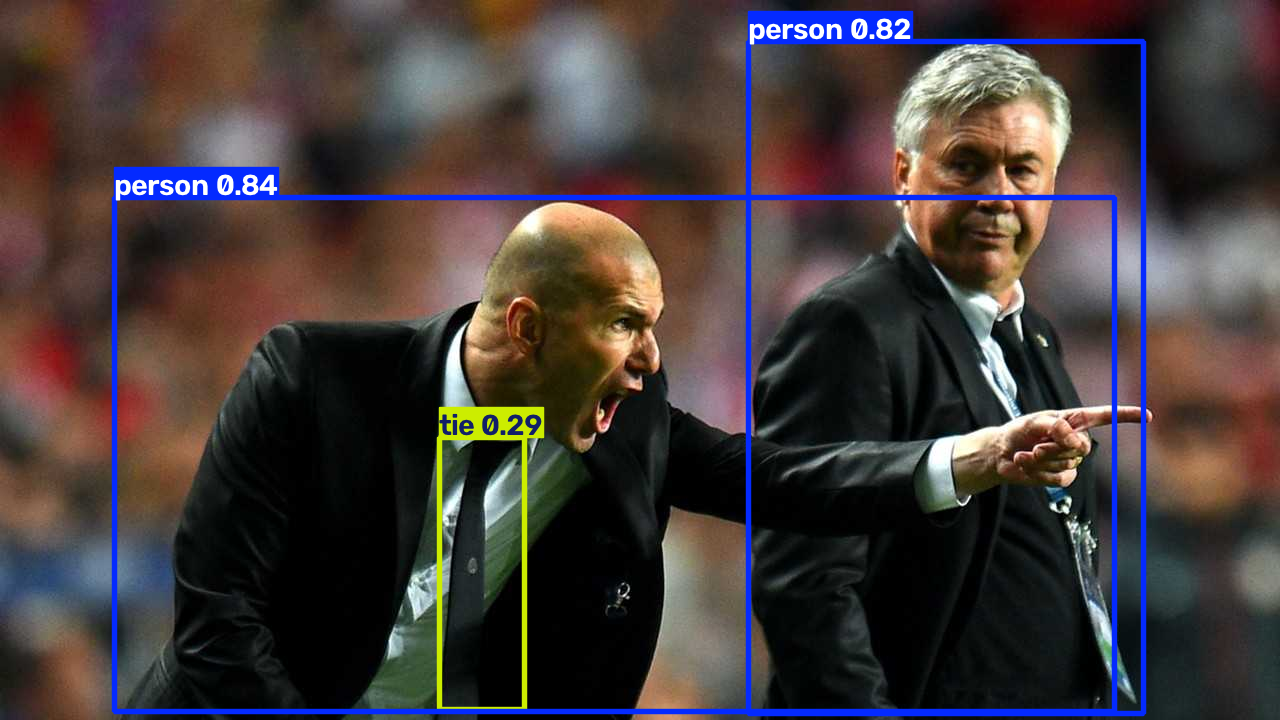

In [2]:
from ultralytics import YOLO
import cv2
from google.colab.patches import cv2_imshow

# Загружаем предобученную модель (nano-версия, самая быстрая)
model = YOLO('yolov8n.pt')
# Отправляем картинку в сеть
results = model("https://ultralytics.com/images/zidane.jpg")

# Превращаем результат в картинку с рамками и показываем
annotated_frame = results[0].plot()
cv2_imshow(annotated_frame)

Смотрим, что в результате внутри

In [3]:
# Извлекаем найденные объекты (Bounding Boxes)
boxes = results[0].boxes

for box in boxes:
    cls_id = int(box.cls[0])          # Номер класса
    cls_name = model.names[cls_id]    # Имя класса ("person", "tie")
    conf = float(box.conf[0])         # Уверенность (Confidence) от 0 до 1
    xyxy = box.xyxy[0].tolist()       # Координаты рамки [x1, y1, x2, y2]

    print(f"Класс: {cls_name:10s} | Confidence: {conf:.2%} | Координаты: {[round(v) for v in xyxy]}")

Класс: person     | Confidence: 83.60% | Координаты: [115, 197, 1114, 712]
Класс: person     | Confidence: 81.90% | Координаты: [748, 42, 1143, 713]
Класс: tie        | Confidence: 29.10% | Координаты: [439, 437, 524, 709]


Пробуем на своей картинке

Выберите изображение на вашем компьютере:


Saving cat1.jpg to cat1.jpg

Загружен файл: cat1.jpg

image 1/1 /content/cat1.jpg: 640x640 1 cat, 12.6ms
Speed: 2.0ms preprocess, 12.6ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


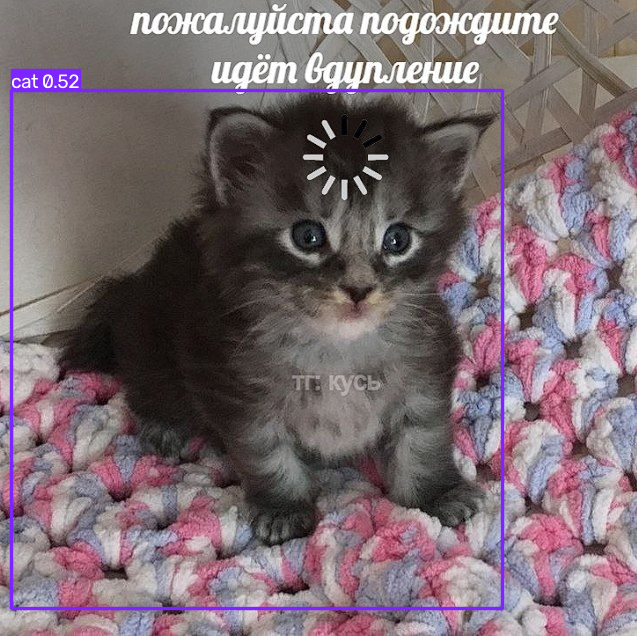

In [4]:
from google.colab import files
from ultralytics import YOLO
from google.colab.patches import cv2_imshow

print("Выберите изображение на вашем компьютере:")
uploaded = files.upload()
image_path = list(uploaded.keys())[0]
print(f"\nЗагружен файл: {image_path}")

model = YOLO("yolov8n.pt")
results = model(image_path)
cv2_imshow(results[0].plot())

Загрузка датасета Африка вайб (Проект Африка, кто понял, тот понял))

In [5]:
import os
import shutil

# 1. Удаляем всё старое, чтобы ничего не мешало
if os.path.exists("/content/african-wildlife"): shutil.rmtree("/content/african-wildlife")
if os.path.exists("/content/african-wildlife.zip"): os.remove("/content/african-wildlife.zip")
if os.path.exists("/content/images"): shutil.rmtree("/content/images")
if os.path.exists("/content/labels"): shutil.rmtree("/content/labels")

# 2. Скачиваем архив
!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/african-wildlife.zip

# 3. Создаем ЧИСТУЮ папку и распаковываем строго туда (флаг -o игнорирует любые вопросы)
!mkdir -p /content/african-wildlife
!unzip -q -o african-wildlife.zip -d /content/african-wildlife/

print("Скачивание и распаковка завершены.")

Скачивание и распаковка завершены.


In [6]:
import os
import shutil

# Сносим все старые папки и архивы
for path in ["/content/datasets", "/content/clean_dataset", "/content/african-wildlife", "african-wildlife.zip"]:
    if os.path.exists(path):
        if os.path.isdir(path): shutil.rmtree(path)
        else: os.remove(path)

print(" Очистка завершена. Мы начинаем с чистого листа.")

 Очистка завершена. Мы начинаем с чистого листа.


**Дообучение**

In [8]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')

results = model.train(
    data='african-wildlife.yaml',
    epochs=15,
    imgsz=640,
    batch=16
)

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

Предсказание модели на изображениях из тестовой выборки

Ищем картинки по всей папке datasets...
 Найдено 1501 картинок. Запускаем детекцию на первых 3-х...

0: 640x640 1 zebra, 9.8ms
1: 640x640 1 rhino, 9.8ms
2: 640x640 1 rhino, 9.8ms
Speed: 1.7ms preprocess, 9.8ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


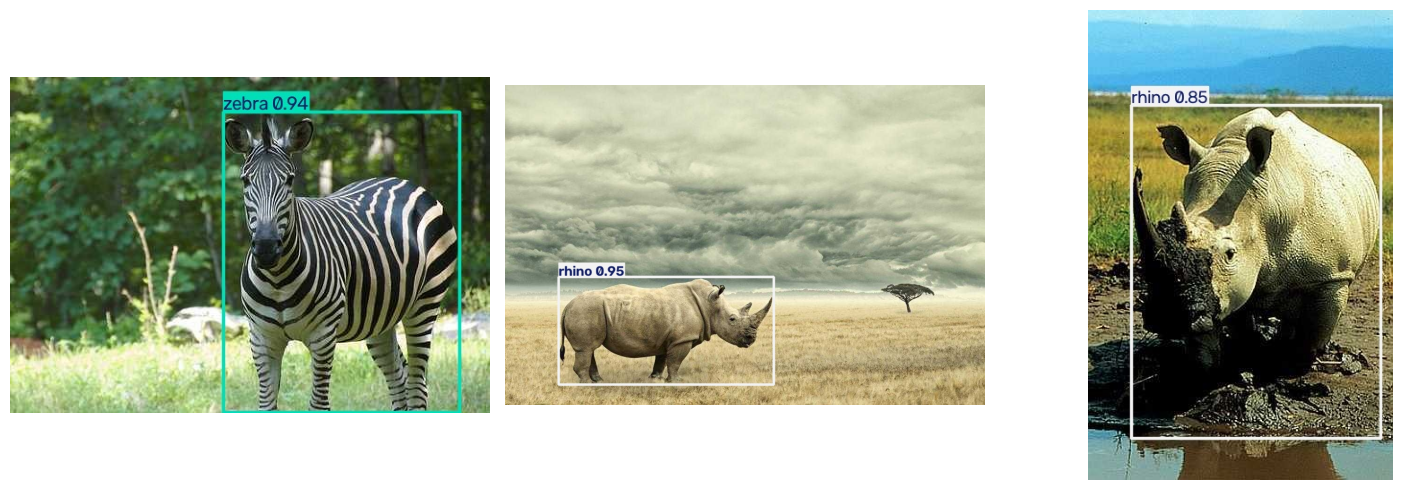

In [10]:
import os
import glob
from PIL import Image
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Загружаем нашу обученную модель
best_model = YOLO("runs/detect/train/weights/best.pt")

# Ищем картинки для теста
test_images = glob.glob("/content/datasets/african-wildlife/val/images/*.jpg")
test_images += glob.glob("/content/datasets/african-wildlife/valid/images/*.jpg")

if not test_images:
    print("Ищем картинки по всей папке datasets...")
    test_images = glob.glob("/content/datasets/**/*.jpg", recursive=True)

if not test_images:
    print(" Картинки не найдены. Твари..")
else:
    print(f" Найдено {len(test_images)} картинок. Запускаем детекцию на первых 3-х...")

    #ПИСАТЬ ТУТ
    best_model.predict(
        source=test_images[:3],
        save=True,
        conf=0.4,
        exist_ok=True
    )


    # Выводим результат
    pred_images = glob.glob("/content/runs/detect/predict/*.jpg")

    if pred_images:
        fig, axes = plt.subplots(1, len(pred_images), figsize=(15, 5))
        if len(pred_images) == 1: axes = [axes]
        for ax, img_path in zip(axes, pred_images):
            ax.imshow(Image.open(img_path))
            ax.axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print("Не удалось сохранить предсказания.")

Тест на своей картинке

Saving zebra1.jpg to zebra1.jpg

image 1/1 /content/zebra1.jpg: 608x640 3 zebras, 14.0ms
Speed: 2.0ms preprocess, 14.0ms inference, 1.4ms postprocess per image at shape (1, 3, 608, 640)


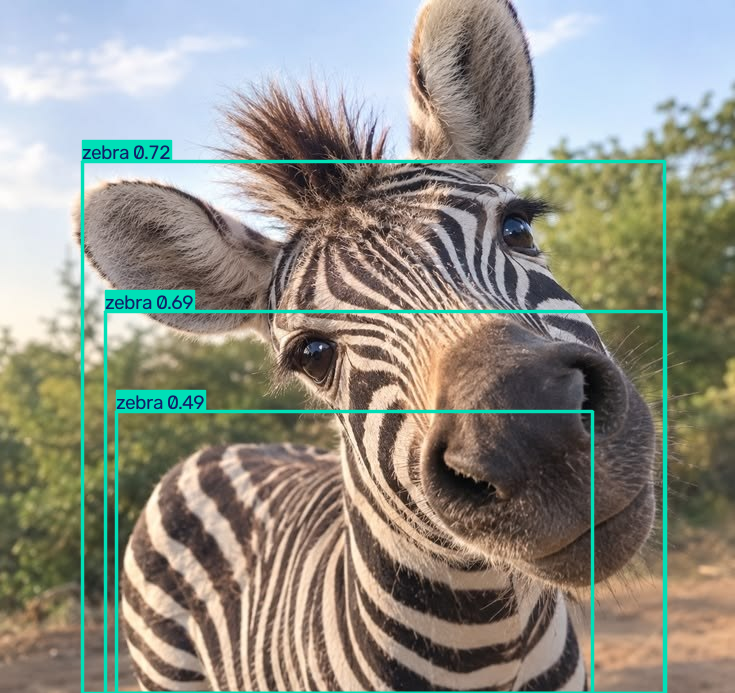

In [11]:
from google.colab import files
from ultralytics import YOLO
from google.colab.patches import cv2_imshow

uploaded = files.upload()

if uploaded:
    img_path = list(uploaded.keys())[0]

    # Загружаем нашу обученную модель
    best_model = YOLO("runs/detect/train/weights/best.pt")

    # Запускаем предсказание на загруженной картинке
    results=best_model.predict(source=img_path, conf=0.4)
    cv2_imshow(results[0].plot())
